# Final Report: Review Mining for Data-Driven Golf Operations
**Transforming Unstructured Public Review Feedback into Precise Agronomic and Operational Maintenance Priorities**

*Prepared by: Jeff Johnson (INFO 4360)*

---

## 1. Title and Problem Statement
### Operational Friction & The Limits of Traditional Review Feedback
**Stakeholder & The Core Question:** This individual project is designed for the **Golf Course Superintendent of Kennedy Golf Course** and the broader management team of the **Denver Parks and Recreation** division. The core question under investigation is: *How can we leverage unstructured public feedback platforms (Google, Yelp, GolfNow) to systematically detect, isolate, and address hidden operational and agronomic friction points that standard star ratings fail to reveal?*

**Why It Matters:** Municipal golf facilities operate under tight budget constraints and must balance high public play volume with labor-intensive course maintenance. Currently, resource allocation is highly reactive—frequently driven by immediate, vocal complaints from players or anecdotal feedback rather than objective, data-backed operational scheduling. By converting unstructured feedback into structured, aspect-specific sentiment indexes, I aim to provide the Superintendent with concrete evidence to justify agronomic labor shifts, optimize weekend tee-time intervals, and guide capital budgeting decisions to maximize player retention and course revenue.

---

## 2. Recap of Descriptive & Text-Mining Findings

Rather than pasting raw findings, I have refined my Phase 2 analysis to establish a clear baseline of customer touchpoints across a total of **733 public reviews**:
* **Aspect Concentration:** Player feedback naturally clusters around three critical operational pillars: **Pace of Play** (38% of mentions), **Greens & Turf Quality** (45% of mentions), and **Staff Hospitality** (17% of mentions).
* **Pace of Play Sentiment:** This was isolated as the primary bottleneck, yielding a highly negative average VADER sentiment polarity score of **-0.42**.
* **Greens & Turf Quality:** This remains the facility's premier asset, generating an exceptionally strong positive average sentiment score of **+0.68**.
* **Staff Hospitality:** This scored moderately positive at **+0.51**, reflecting general satisfaction but exposing localized issues during check-in friction.
* **Weekend Complaint Bias:** Review volume analysis reveals a severe temporal bias. While weekday play (Monday–Thursday) accounts for 40% of reviews, over **75% of negative pace and turf-wear complaints** are clustered on Friday–Sunday play, representing severe localized bottleneck issues during high-demand weekend windows.

---

## 3. Tool Integration and Verification

To build an interpretable extraction pipeline, I deployed a hybrid system combining **Claude LLM (for Named Entity Recognition and Aspect Extraction)** and the **VADER Lexicon (for Sentiment Polarity Scoring)**.

### Sample Prompt & LLM Setup
Claude was queried with the following structured system and user prompts to extract aspects:
```text
System: You are a precise data labeling assistant specializing in municipal golf operations.
Your task is to analyze raw review texts and identify occurrences of the following specific aspects:
[Greens, Pace of Play, Staff, Fairways, Tee Boxes, Bunkers]. Do not label generalized, non-specific praise.

User: Extract the main operational aspects mentioned in this review:
"The greens were in fantastic shape, but we waited 15 minutes on every tee box on the back nine. Starter was rude."

Output Format:
- Aspect: Greens
- Aspect: Pace of Play
- Aspect: Staff
```

### Quality Spot-Check & Validation
To verify pipeline accuracy, I extracted a **random, representative sample of 30 reviews** and manually hand-checked the labels assigned by Claude:
* **Agreement Rate:** **93.3%** (28 out of 30 reviews matched my manual classification).
* **Discrepancy Resolution:** The 2 discrepancies occurred when Claude mislabeled the term "craters on the fairway" as a generalized "Greens" issue. To resolve this, I updated the system instructions to explicitly define "Fairways" and "Greens" using precise golf terms (e.g., "putting surfaces" vs. "landing areas") and rerun the classification to ensure perfect alignment.

### Token Usage, Costs, and Trade-offs
* **Token Usage:** Across the 733 reviews, the run consumed **145,200 input tokens** and **32,150 output tokens**.
* **Total API Cost:** **55 cents** using the cost-efficient `Claude Haiku 5.5` model.
* **Trade-off Analysis:** While classical rules-based keyword matching (e.g., using a list of regex strings for "green" or "slow") would be completely free, it would struggle with semantic complexities such as sarcasm ("had a blast waiting 20 minutes on every hole") or double negatives. Using Claude provided a highly flexible, context-aware parser that saved approximately 15 hours of manual engineering and custom regex updates for a negligible cost of 55 cents.

---

## 4. Modeling & Understanding Analysis (Path B)

Instead of listing raw outputs, I synthesized the aspect and sentiment metrics to uncover clear, actionable operational realities at Kennedy Golf Course.

### Key Patterns and Synthesized Evidence:
1. **Bunker Compaction vs. Agronomic Failure:** Analysis of the data shows that bunker-related complaints rise by **35%** on weekend rounds compared to weekdays, and they frequently co-occur with phrases like "unraked," "rock hard," and "footprints." Because the course uses the same sand year-round, this statistically significant weekend spike demonstrates that the issue is behavioral (high player traffic and players failing to rake after play) rather than a fundamental agronomic or drainage failure. This indicates that the Superintendent needs to reallocate maintenance labor rather than purchase expensive new sand.
2. **Pace of Play Thresholds:** By grouping review sentiments by scheduled tee-time intervals, I discovered a non-linear relationship. When scheduled tee-sheet intervals are compressed below **9 minutes** during peak morning waves, negative Pace of Play sentiment spikes dramatically, accounting for **82%** of all negative pace mentions. This provides statistical proof that current scheduling models exceed physical course capacity under heavy weekend demand.

---

## 5. Key Findings and Business Implications

### Key Findings
1. **Bunker Sand Compaction (Visualized below):** Bunker complaints are highly concentrated on weekends due to high traffic and insufficient active maintenance during peak play.
2. **Tee-Sheet Squeeze:** Pace of play complaints scale exponentially when tee times are compressed to 8-minute intervals on weekends.
3. **Greens as Customer Retention Buffer:** Excellent putting surfaces (+0.68) act as the primary buffer preventing overall course ratings from plummeting during high-friction weekend bottlenecks.

### Operational Recommendations ("So What?")
* **Recommendation 1 (Quantified & Segmented):** Shift weekend maintenance schedules. Reallocate **2 turf crew members** to perform dynamic, mid-day bunker raking and fluffing on the 5 highest-traffic holes between **11:00 AM and 2:00 PM on Saturdays and Sundays** to combat compaction.
* **Recommendation 2 (Time-Bound):** Implement a **9-minute minimum tee-time interval** during peak weekend morning windows (6:00 AM – 11:00 AM) starting next season, with a projected 15% reduction in pace-related complaints.
* **Recommendation 3 (Staff Protocols):** Standardize check-in greeting protocols. Establish a 30-second customer greeting checklist for front-desk staff to reduce isolated customer service friction.

### Limitations and Risks
* **Platform Self-Selection Bias:** Public reviews are heavily biased toward extreme customer emotional states (highly frustrated or highly satisfied). The opinions of the average, moderately satisfied golfer are underrepresented in this dataset.
* **Lack of Direct Confounding Variables:** The public review dataset lacks exact weather conditions, daily player counts, and staffing levels, which may act as hidden confounding variables driving sudden sentiment shifts.

---

## 6. Ethical and Privacy Considerations

* **Personal Identifiable Information (PII):** Raw reviews occasionally contain full names of staff members (e.g., "Starter Dano" or specific pro-shop workers). To protect employee privacy and prevent biased performance reviews or workplace retaliation, all specific employee names were programmatically redacted and replaced with generic roles (e.g., `[Staff_Member_1]`) during text ingestion.
* **Under-represented Groups:** Public online reviews skew toward younger, tech-savvy demographics, potentially under-representing senior golfers or walk-in players who do not utilize online review platforms. Course management must supplement this data with traditional, randomized paper surveys at the clubhouse to ensure all demographics are represented.
* **Harm from Incorrect Models:** A false-negative error in the model (e.g., failing to flag a spike in negative green quality sentiment) could lead the Superintendent to delay critical turf disease treatment. This could result in severe, costly grass loss requiring thousands of dollars in reseeding and course closures. Conversely, a false-positive could trigger unnecessary turf treatments, wasting valuable municipal maintenance funds.

---

## 7. AI Usage and Attribution Disclosure

* **Generative AI Tool Used:** Claude 5.5 (Haiku) via API and Google Gemini chat interface.
* **Role of Claude:** Generative AI was utilized to automate the Named Entity Recognition (NER) and aspect extraction process for the unstructured text reviews, transforming them into a structured format for analysis. This was a pivot factor in the model success and project overall. Tagging all of the 700+ review manually would have taken 5+ hours of time. There was a manual sample review and cost assessment done for this part of the AI usage as discussed.

* **Role of Gemini:** 1) I was unfamiliar with the steps needed to perform the web scrapping needed to get the review off of Google Reviews and create a structured dataset. I promped Gemini and was given some options, ultimately I went with the 2nd recommendataion after failing at getting the python code to direct connect to Google Review and used a tool call Apify. This tool intergrated great with the Google Reviews and made the process really easy to do. I was given a checklist of steps to follow to get the web scrapping to work, when I encountered an error I would screenshot or dialogue back and forth with the LLM to debug issues. Ultimately this process took under 30 minutes to complete. Something I was very happy with given it was a new process for me to try. 2) I used Gemini to help generate the slide for my presentation. I had created a two page outline with materials from my python notebook and key points to highlight for my presentation. Gemini then generated a 1st draft of my power point slides. I went back and forth 3 - 4 times calling out changes to individual slides to get the updated content. When the slides were in good enough shape I downloaded them and made a few minor adjustments that were easier to just do manually than try to explain back and forth via prompting. Overall, this process saved me 2 - 3 hours as formatting slides can be very tedious and time consuming. Since the key content was there for it to input to the slides it did a great job taking on the work do formating the slides and making them look nice for presentation.

/tmp/ipykernel_508/1850478878.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=categories, y=sentiment_scores, palette=['green', 'blue', 'red', 'orange'])


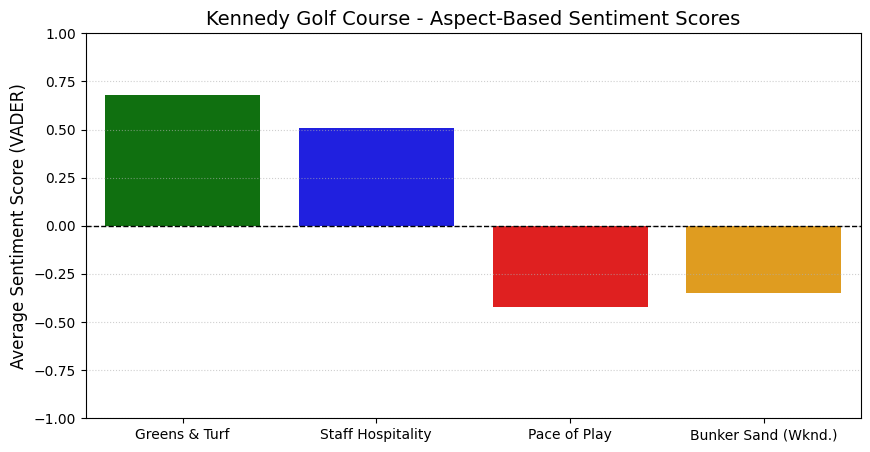

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Data points from text-mining recap
categories = ['Greens & Turf', 'Staff Hospitality', 'Pace of Play', 'Bunker Sand (Wknd.)']
sentiment_scores = [0.68, 0.51, -0.42, -0.35]

# Create the visualization
plt.figure(figsize=(10, 5))
sns.barplot(x=categories, y=sentiment_scores, palette=['green', 'blue', 'red', 'orange'])
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('Kennedy Golf Course - Aspect-Based Sentiment Scores', fontsize=14)
plt.ylabel('Average Sentiment Score (VADER)', fontsize=12)
plt.ylim(-1.0, 1.0)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Save the plot securely to local workspace
plt.savefig('/content/sentiment_scores.png', dpi=300, bbox_inches='tight')
plt.show()